# 2.1 Model comparison

All trained models are checked here on the val images, with the same code for every model.

- Step 1, is there a fracture: each image gets the largest cell score in its grid. That number gives the ROC AUC. A cut-off then turns it into a yes or no, which gives recall and specificity. The cut-off is picked on val with the same rule as 1.4, the best balanced accuracy.
- Step 2, where is the fracture: done on every val image with a fracture, also the ones step 1 missed. The top cell gives the first box. A second or third box comes only from another cell that scores above the cut-off.

Files:
- reads `val_cell_predictions.npz` from each run folder of 1.4 and 1.5, and `graz.csv`, `graz_boxes.csv` and the image array from 0.1
- writes `models/2.1_model-comparison_fahim/val_metrics.csv`, one row per run
- the test set is not used here

## Setup

Every 1.4 and 1.5 run folder that has val predictions is scored.

In [1]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score, roc_curve

from snap.config import MODELS_DIR, PROCESSED_DATA_DIR

# grid and image size
GRID_ROWS = 32
GRID_COLS = 16
CELL_SIZE = 16
IMAGE_WIDTH = 256
IMAGE_HEIGHT = 512

# scoring settings
IOU_MATCH = 0.5
FIRST_CUTOFF = 0.5
MAX_BOXES = 3

# fixed seed for the example images at the end
EXAMPLE_SEED = 0

OUT_DIR = MODELS_DIR / '2.1_model-comparison_fahim'
OUT_DIR.mkdir(parents=True, exist_ok=True)

RUNS = []
for notebook_folder in ['1.4_grid-baseline_zahra', '1.5_small-cnn-grid_lloyd']:
    folder = MODELS_DIR / notebook_folder
    for predictions_file in sorted(folder.glob('*_seed*/val_cell_predictions.npz')):
        run_name = predictions_file.parent.name
        RUNS.append(notebook_folder + '/' + run_name)


def short_name(run):
    # '1.4_grid-baseline_zahra/hog-sift-gb_all_seed42' becomes 'gb all seed42'
    name = run.split('/')[-1]
    name = name.replace('hog-sift-', '')
    name = name.replace('small-cnn', 'cnn')
    name = name.replace('_', ' ')
    return name


# each run keeps the same color in every plot
RUN_COLORS = {}
for k, run in enumerate(RUNS):
    RUN_COLORS[run] = f'C{k}'

for run in RUNS:
    print(short_name(run), '<-', run)

2026-11-23 20:48:48.488 | INFO     | snap.config:<module>:11 - PROJ_ROOT path is: E:\CCNY\CSC I1910\Project\wrist-fracture-detection


gb all-castpairs seed42 <- 1.4_grid-baseline_zahra/hog-sift-gb_all-castpairs_seed42
gb all seed42 <- 1.4_grid-baseline_zahra/hog-sift-gb_all_seed42
lr all-castpairs seed42 <- 1.4_grid-baseline_zahra/hog-sift-lr_all-castpairs_seed42
lr all seed42 <- 1.4_grid-baseline_zahra/hog-sift-lr_all_seed42
cnn all-castpairs seed42 <- 1.5_small-cnn-grid_lloyd/small-cnn_all-castpairs_seed42


## Val labels and true boxes

Boxes are `x0, y0, x1, y1` in pixels of the 256x512 image.

In [2]:
graz = pd.read_csv(PROCESSED_DATA_DIR / 'graz.csv')
boxes = pd.read_csv(PROCESSED_DATA_DIR / 'graz_boxes.csv')
images = np.load(PROCESSED_DATA_DIR / 'graz_256x512_u8.npy', mmap_mode='r')

# val image n is row val_rows[n] of graz.csv
val_rows = np.flatnonzero(graz['split'] == 'val')
val = graz.iloc[val_rows].reset_index(drop=True)
val_labels = val['label'].to_numpy()
val_cast = val['cast'].to_numpy()

fracture_boxes = boxes[boxes['name'] == 'fracture']
true_boxes = []
for filestem in val['filestem']:
    image_boxes = fracture_boxes[fracture_boxes['filestem'] == filestem]
    box_list = []
    for x0, y0, x1, y1 in image_boxes[['x0', 'y0', 'x1', 'y1']].to_numpy():
        box_list.append((x0, y0, x1, y1))
    true_boxes.append(box_list)

for n in range(len(val)):
    has_box = len(true_boxes[n]) > 0
    assert has_box == (val_labels[n] == 1)

fractured_count = np.sum(val_labels == 1)
normal_count = np.sum(val_labels == 0)
print(f'{len(val)} val images: {fractured_count} fractured, {normal_count} normal')

3202 val images: 2208 fractured, 994 normal


## Helper functions

In [3]:
def iou_of_two_boxes(first_box, second_box):
    # overlap area divided by the area the two boxes cover together
    overlap_width = min(first_box[2], second_box[2]) - max(first_box[0], second_box[0])
    overlap_height = min(first_box[3], second_box[3]) - max(first_box[1], second_box[1])
    if overlap_width <= 0 or overlap_height <= 0:
        return 0.0
    overlap = overlap_width * overlap_height
    first_area = (first_box[2] - first_box[0]) * (first_box[3] - first_box[1])
    second_area = (second_box[2] - second_box[0]) * (second_box[3] - second_box[1])
    return overlap / (first_area + second_area - overlap)


def cell_center(row, column):
    center_x = CELL_SIZE * column + CELL_SIZE / 2
    center_y = CELL_SIZE * row + CELL_SIZE / 2
    return center_x, center_y


def box_from_cell(row, column, distances):
    # the cell center plus the 4 predicted distances, kept inside the image
    center_x, center_y = cell_center(row, column)
    left, top, right, bottom = distances[row, column]
    x0 = max(center_x - left, 0)
    y0 = max(center_y - top, 0)
    x1 = min(center_x + right, IMAGE_WIDTH)
    y1 = min(center_y + bottom, IMAGE_HEIGHT)
    return (float(x0), float(y0), float(x1), float(y1))

In [4]:
def boxes_for_image(scores, distances, threshold):
    # copy, so the scores of the run are not changed
    scores = scores.copy()
    drawn = []
    while len(drawn) < MAX_BOXES:
        best_cell = np.argmax(scores)
        row = best_cell // GRID_COLS
        column = best_cell % GRID_COLS
        # the first box is always drawn, later ones need a score above the threshold
        if len(drawn) > 0 and scores[row, column] <= threshold:
            break
        box = box_from_cell(row, column, distances)
        drawn.append(box)

        # this cell and every cell with its center inside the box can't start another box
        scores[row, column] = -1
        for other_row in range(GRID_ROWS):
            for other_column in range(GRID_COLS):
                center_x, center_y = cell_center(other_row, other_column)
                if box[0] <= center_x <= box[2] and box[1] <= center_y <= box[3]:
                    scores[other_row, other_column] = -1
    return drawn

In [5]:
def recall_and_specificity(image_scores, image_labels, cutoff):
    # an image above the cut-off is called fractured
    fractured_called = image_scores[image_labels == 1] > cutoff
    normals_called_normal = image_scores[image_labels == 0] <= cutoff
    recall = np.mean(fractured_called)
    specificity = np.mean(normals_called_normal)
    return recall, specificity

In [6]:
def pick_cutoff(image_scores, image_labels):
    # tries 0.5 and every image score above it
    cutoffs_to_try = [FIRST_CUTOFF]
    for score in np.unique(image_scores):
        if score > FIRST_CUTOFF:
            cutoffs_to_try.append(float(score))

    best_cutoff = None
    best_balanced = -1.0
    best_recall = -1.0
    # going from low to high, so on a full tie the lower cut-off stays
    for cutoff in cutoffs_to_try:
        recall, specificity = recall_and_specificity(image_scores, image_labels, cutoff)
        balanced = (recall + specificity) / 2
        better = balanced > best_balanced
        same_but_more_recall = balanced == best_balanced and recall > best_recall
        if better or same_but_more_recall:
            best_cutoff = cutoff
            best_balanced = balanced
            best_recall = recall
    return best_cutoff

## Checks on small examples

Each function is tested on a small case with the answer worked out by hand.
- IoU: two 10x10 boxes overlapping in a 5x5 square give 25 / 175.
- Boxes: a 0.9 cell at row 10, column 5 with 20 px on each side gives the box (68, 148, 108, 188). The 0.8 cell next to it is inside that box, so it gives no box. A 0.7 cell further down gives a second box at threshold 0.5, but not at 0.75.
- Cut-off: scores 0.9, 0.8, 0.4, 0.3, 0.1 with labels 1, 0, 1, 0, 0. At 0.5, recall is 1/2 and specificity 2/3. Of the cut-offs tried (0.5, 0.8, 0.9), 0.8 has the best balanced accuracy.

In [7]:
assert abs(iou_of_two_boxes((0, 0, 10, 10), (5, 5, 15, 15)) - 25 / 175) < 1e-9
assert iou_of_two_boxes((0, 0, 10, 10), (20, 20, 30, 30)) == 0.0

check_scores = np.zeros((GRID_ROWS, GRID_COLS), dtype=np.float32)
check_scores[10, 5] = 0.9
check_scores[10, 6] = 0.8
check_scores[25, 5] = 0.7
check_distances = np.full((GRID_ROWS, GRID_COLS, 4), 20, dtype=np.float32)
check_boxes = boxes_for_image(check_scores, check_distances, 0.5)
assert check_boxes == [(68.0, 148.0, 108.0, 188.0), (68.0, 388.0, 108.0, 428.0)]
assert len(boxes_for_image(check_scores, check_distances, 0.75)) == 1

check_image_scores = np.array([0.9, 0.8, 0.4, 0.3, 0.1])
check_labels = np.array([1, 0, 1, 0, 0])
check_recall, check_specificity = recall_and_specificity(check_image_scores, check_labels, 0.5)
assert check_recall == 0.5
assert abs(check_specificity - 2 / 3) < 1e-9
assert pick_cutoff(check_image_scores, check_labels) == 0.8
print('all checks passed')

all checks passed


## Score each run

In [8]:
def load_val_predictions(run):
    # scores (n, 32, 16) and distances (n, 32, 16, 4) in pixels
    with np.load(MODELS_DIR / run / 'val_cell_predictions.npz') as predictions:
        assert np.array_equal(predictions['rows'], val_rows), f'{run}: rows differ from the val rows of graz.csv'
        scores = predictions['scores']
        distances = predictions['distances']
    return scores, distances


def largest_cell_score(scores):
    # one number per image: its highest cell score
    return scores.reshape(len(scores), -1).max(axis=1)

In [9]:
def box_metrics(scores, distances, cutoff):
    # step 2, on every fractured val image
    first_box_ious = []
    boxes_drawn = 0
    boxes_on_a_fracture = 0
    fractures = 0
    fractures_found = 0
    for n in range(len(val)):
        if val_labels[n] == 0:
            continue
        drawn = boxes_for_image(scores[n], distances[n], cutoff)

        best_iou = 0.0
        for true_box in true_boxes[n]:
            best_iou = max(best_iou, iou_of_two_boxes(drawn[0], true_box))
        first_box_ious.append(best_iou)

        for box in drawn:
            boxes_drawn += 1
            for true_box in true_boxes[n]:
                if iou_of_two_boxes(box, true_box) >= IOU_MATCH:
                    boxes_on_a_fracture += 1
                    break

        for true_box in true_boxes[n]:
            fractures += 1
            for box in drawn:
                if iou_of_two_boxes(box, true_box) >= IOU_MATCH:
                    fractures_found += 1
                    break

    first_box_ious = np.array(first_box_ious)
    return {'first_box_mean_iou': np.mean(first_box_ious),
            'first_box_hit_rate': np.mean(first_box_ious >= IOU_MATCH),
            'boxes_per_fractured_image': boxes_drawn / len(first_box_ious),
            'box_recall': fractures_found / fractures,
            'box_precision': boxes_on_a_fracture / boxes_drawn}

In [10]:
def score_run(run):
    scores, distances = load_val_predictions(run)

    # step 1, on all val images
    image_scores = largest_cell_score(scores)
    cutoff = pick_cutoff(image_scores, val_labels)
    recall, specificity = recall_and_specificity(image_scores, val_labels, cutoff)
    row = {'run': run,
           'image_roc_auc': roc_auc_score(val_labels, image_scores),
           'cutoff': cutoff,
           'recall': recall,
           'specificity': specificity}

    row.update(box_metrics(scores, distances, cutoff))
    return row

All box columns use only the fractured val images. `first_box_hit_rate` is the share of them whose first box has IoU >= 0.5 with a true box. `box_precision` counts only the boxes drawn on them.

In [11]:
metric_rows = []
for run in RUNS:
    metric_rows.append(score_run(run))
val_metrics = pd.DataFrame(metric_rows)
val_metrics.to_csv(OUT_DIR / 'val_metrics.csv', index=False)

table = val_metrics.copy()
table['run'] = table['run'].map(short_name)
table.set_index('run').round(3)

,image_roc_auc,cutoff,recall,specificity,first_box_mean_iou,first_box_hit_rate,boxes_per_fractured_image,box_recall,box_precision
run,,,,,,,,,
gb all-castpairs seed42,0.744,0.944,0.750,0.683,0.406,0.490,1.503,0.459,0.481
gb all seed42,0.716,0.940,0.807,0.615,0.355,0.414,1.620,0.447,0.435
lr all-castpairs seed42,0.489,0.980,0.152,0.899,0.373,0.399,1.007,0.301,0.397
lr all seed42,0.514,0.972,0.266,0.812,0.368,0.389,1.027,0.296,0.386
cnn all-castpairs seed42,0.951,0.986,0.870,0.920,0.635,0.822,2.043,0.718,0.763


## Plots

Left: step 1 on all val images. Right: step 2 on the fractured ones.

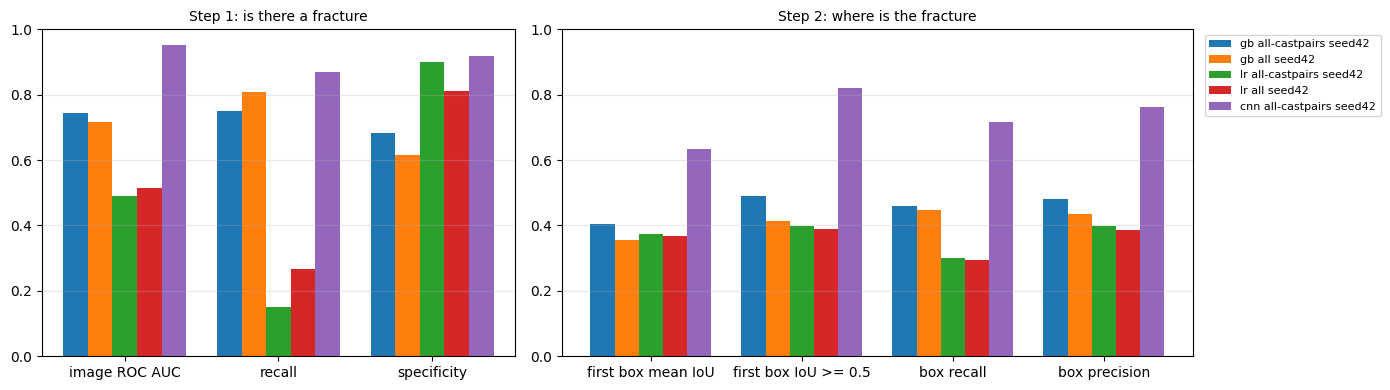

In [12]:
step1_columns = ['image_roc_auc', 'recall', 'specificity']
step2_columns = ['first_box_mean_iou', 'first_box_hit_rate', 'box_recall', 'box_precision']
step1_names = ['image ROC AUC', 'recall', 'specificity']
step2_names = ['first box mean IoU', 'first box IoU >= 0.5', 'box recall', 'box precision']
panels = [(step1_columns, step1_names, 'Step 1: is there a fracture'),
          (step2_columns, step2_names, 'Step 2: where is the fracture')]

fig, axes = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={'width_ratios': [3, 4]})
bar_width = 0.8 / len(RUNS)
for ax, (columns, names, title) in zip(axes, panels):
    positions = np.arange(len(columns))
    for k, run in enumerate(RUNS):
        values = val_metrics.loc[k, columns].to_numpy(dtype=float)
        ax.bar(positions + k * bar_width, values, bar_width, color=RUN_COLORS[run], label=short_name(run))
    ax.set_xticks(positions + bar_width * (len(RUNS) - 1) / 2)
    ax.set_xticklabels(names)
    ax.set_ylim(0, 1)
    ax.set_title(title, fontsize=10)
    ax.grid(axis='y', alpha=0.3)
axes[1].legend(fontsize=8, bbox_to_anchor=(1.01, 1), loc='upper left')
plt.tight_layout()
plt.show()

ROC curve of each run's image score, with a dot at its cut-off. A curve close to the dotted diagonal is no better than guessing.

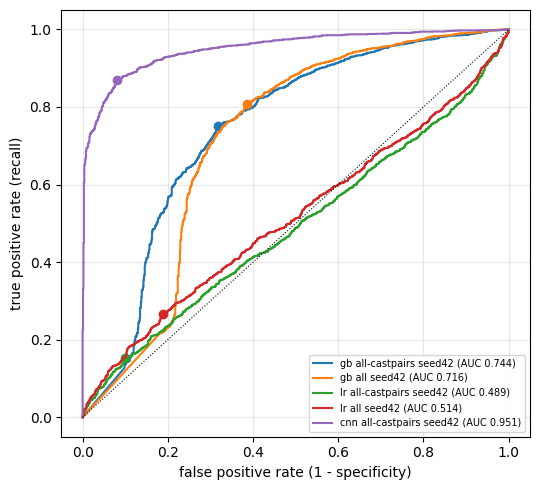

In [13]:
fig, ax = plt.subplots(figsize=(5.5, 5))
for k, run in enumerate(RUNS):
    scores, distances = load_val_predictions(run)
    image_scores = largest_cell_score(scores)
    false_positive_rate, true_positive_rate, _ = roc_curve(val_labels, image_scores)
    run_auc = val_metrics.loc[k, 'image_roc_auc']
    label = f'{short_name(run)} (AUC {run_auc:.3f})'
    ax.plot(false_positive_rate, true_positive_rate, color=RUN_COLORS[run], label=label)

    cutoff_x = 1 - val_metrics.loc[k, 'specificity']
    cutoff_y = val_metrics.loc[k, 'recall']
    ax.plot(cutoff_x, cutoff_y, 'o', color=RUN_COLORS[run])
ax.plot([0, 1], [0, 1], ':', color='black', linewidth=0.8)
ax.set_xlabel('false positive rate (1 - specificity)')
ax.set_ylabel('true positive rate (recall)')
ax.legend(fontsize=7, loc='lower right')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Example images

The runs trained on `all-castpairs`, one column per model, on two val images chosen with `EXAMPLE_SEED`. Top row: a fractured image with no cast. Bottom row: a normal image with a cast. The bottom row checks whether a model reacts to the cast instead of the fracture.

The cell scores are drawn over the X-ray. Dashed white boxes are the true fractures, green boxes are the model's boxes. Here a model draws boxes only on an image it calls fractured. The step 2 numbers above also score the first box on fractured images the model missed. Each title gives the model and what it decided.

In [14]:
def draw_box(ax, box, color, line_width, line_style='-'):
    x0, y0, x1, y1 = box
    rectangle = Rectangle(
        (x0, y0), x1 - x0, y1 - y0,
        fill=False, edgecolor=color,
        linewidth=line_width, linestyle=line_style,
    )
    ax.add_patch(rectangle)


def decision_text(label, image_score, cutoff):
    called_fractured = image_score > cutoff
    if label == 1 and called_fractured:
        return 'fracture found'
    if label == 1:
        return 'fracture missed'
    if called_fractured:
        return 'normal flagged'
    return 'normal correct'


def model_label(run):
    # '1.4_grid-baseline_zahra/hog-sift-gb_all-castpairs_seed42' becomes 'GB'
    name = run.split('/')[-1]
    if name.startswith('hog-sift-gb'):
        return 'GB'
    if name.startswith('hog-sift-lr'):
        return 'LR'
    if name.startswith('small-cnn'):
        return 'CNN'
    return name

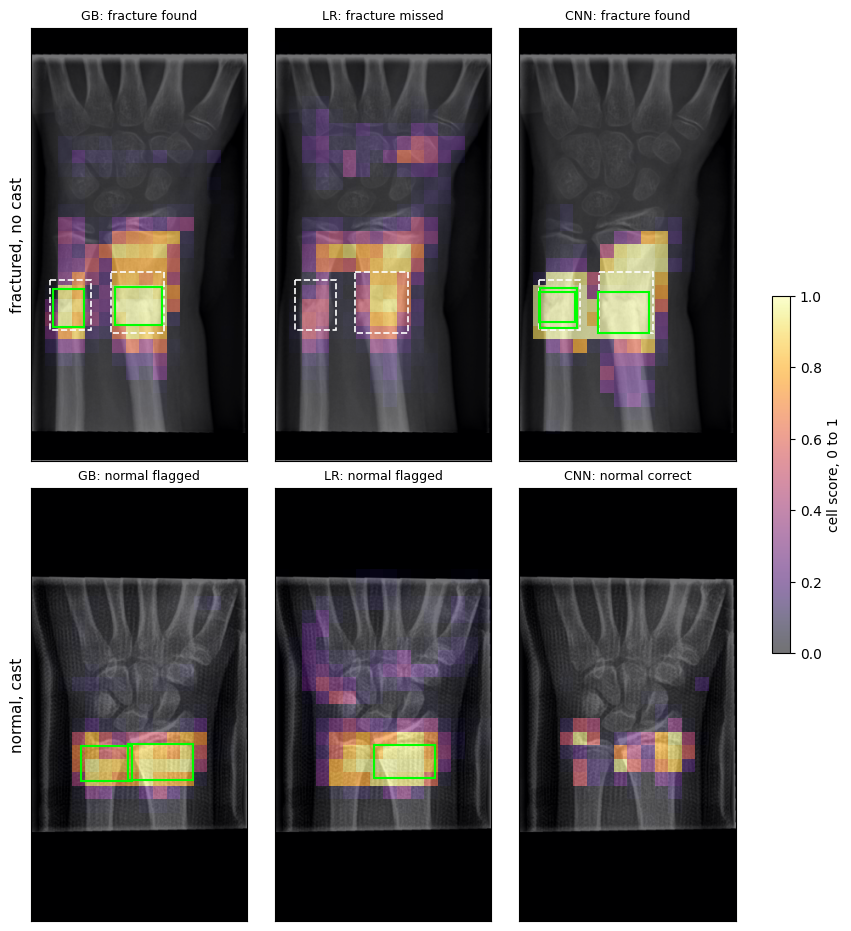

In [15]:
example_runs = []
for run in RUNS:
    if '_all-castpairs_' in run:
        example_runs.append(run)

example_rng = np.random.default_rng(EXAMPLE_SEED)
fractured_no_cast = np.flatnonzero((val_labels == 1) & (val_cast == 0))
normal_with_cast = np.flatnonzero((val_labels == 0) & (val_cast == 1))
example_rows = [example_rng.choice(fractured_no_cast), example_rng.choice(normal_with_cast)]
row_names = ['fractured, no cast', 'normal, cast']

fig, axes = plt.subplots(len(example_rows), len(example_runs),
                         figsize=(2.8 * len(example_runs), 4.6 * len(example_rows)),
                         layout='constrained', squeeze=False)
for column, run in enumerate(example_runs):
    scores, distances = load_val_predictions(run)
    cutoff = val_metrics.loc[RUNS.index(run), 'cutoff']
    for row, n in enumerate(example_rows):
        ax = axes[row, column]
        image_score = scores[n].max()
        ax.imshow(images[val_rows[n]], cmap='gray')
        heatmap = ax.imshow(scores[n], cmap='inferno', alpha=0.55, vmin=0, vmax=1,
                          extent=(0, IMAGE_WIDTH, IMAGE_HEIGHT, 0))
        for true_box in true_boxes[n]:
            draw_box(ax, true_box, 'white', 1.2, '--')
        if image_score > cutoff:
            for box in boxes_for_image(scores[n], distances[n], cutoff):
                draw_box(ax, box, 'lime', 1.5)

        decision = decision_text(val_labels[n], image_score, cutoff)
        ax.set_title(f'{model_label(run)}: {decision}', fontsize=9)
        ax.set_xticks([])
        ax.set_yticks([])
        if column == 0:
            ax.set_ylabel(row_names[row], fontsize=11)
fig.colorbar(heatmap, ax=axes, shrink=0.4, label='cell score, 0 to 1')
plt.show()